# Bivariate and Multivariate Exploratory Data Analysis

## M6.1 — Numerical Features by Traffic Class

### Objective

Compare the distributions of selected numerical network traffic
features between Normal and Attack records.

Datasets are analyzed separately because their feature definitions
and collection methods differ.

All original records are preserved.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

project_dir = (
    current_dir.parent
    if current_dir.name == "notebooks"
    else current_dir
)

print("Project directory:", project_dir)

Project directory: C:\Users\fatim\Documents\network-intrusion-eda


In [2]:
nsl_columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "attack_type", "difficulty_level"
]

nsl_train = pd.read_csv(
    project_dir / "data/raw/nsl_kdd/KDDTrain+.txt",
    header=None,
    names=nsl_columns
)

unsw_train = pd.read_csv(
    project_dir / "data/raw/unsw_nb15/UNSW_NB15_training-set.csv"
)

print("NSL-KDD:", nsl_train.shape)
print("UNSW-NB15:", unsw_train.shape)

NSL-KDD: (125973, 43)
UNSW-NB15: (175341, 45)


In [3]:
nsl_analysis = nsl_train.copy(deep=True)
unsw_analysis = unsw_train.copy(deep=True)

nsl_analysis["traffic_class"] = np.where(
    nsl_analysis["attack_type"] == "normal",
    "Normal",
    "Attack"
)

unsw_analysis["traffic_class"] = unsw_analysis["label"].map({
    0: "Normal",
    1: "Attack"
})

print("NSL-KDD:")
print(nsl_analysis["traffic_class"].value_counts())

print("\nUNSW-NB15:")
print(unsw_analysis["traffic_class"].value_counts())

NSL-KDD:
traffic_class
Normal    67343
Attack    58630
Name: count, dtype: int64

UNSW-NB15:
traffic_class
Attack    119341
Normal     56000
Name: count, dtype: int64


In [4]:
feature_config = {
    "NSL-KDD": {
        "data": nsl_analysis,
        "features": ["duration", "src_bytes", "dst_bytes"]
    },
    "UNSW-NB15": {
        "data": unsw_analysis,
        "features": ["dur", "sbytes", "dbytes"]
    }
}

summary_rows = []

for dataset_name, config in feature_config.items():

    df = config["data"]

    for feature in config["features"]:

        for traffic_class in ["Normal", "Attack"]:

            values = df.loc[
                df["traffic_class"] == traffic_class,
                feature
            ]

            summary_rows.append({
                "Dataset": dataset_name,
                "Feature": feature,
                "Traffic Class": traffic_class,
                "Count": len(values),
                "Mean": values.mean(),
                "Median": values.median(),
                "90th Percentile": values.quantile(0.90)
            })

class_feature_summary = pd.DataFrame(summary_rows)

display(class_feature_summary.round(3))

,Dataset,Feature,Traffic Class,Count,Mean,Median,90th Percentile
0,NSL-KDD,duration,Normal,67343,168.587,0.000,1.000
1,NSL-KDD,duration,Attack,58630,423.321,0.000,0.000
2,NSL-KDD,src_bytes,Normal,67343,13133.279,233.000,1181.800
3,NSL-KDD,src_bytes,Attack,58630,82820.141,0.000,28.000
4,NSL-KDD,dst_bytes,Normal,67343,4329.685,379.000,7128.000
5,NSL-KDD,dst_bytes,Attack,58630,37524.482,0.000,0.000
6,UNSW-NB15,dur,Normal,56000,1.017,0.039,1.197
7,UNSW-NB15,dur,Attack,119341,1.520,0.000,1.676
8,UNSW-NB15,sbytes,Normal,56000,4105.703,1470.000,7818.000
9,UNSW-NB15,sbytes,Attack,119341,11068.655,200.000,2190.000


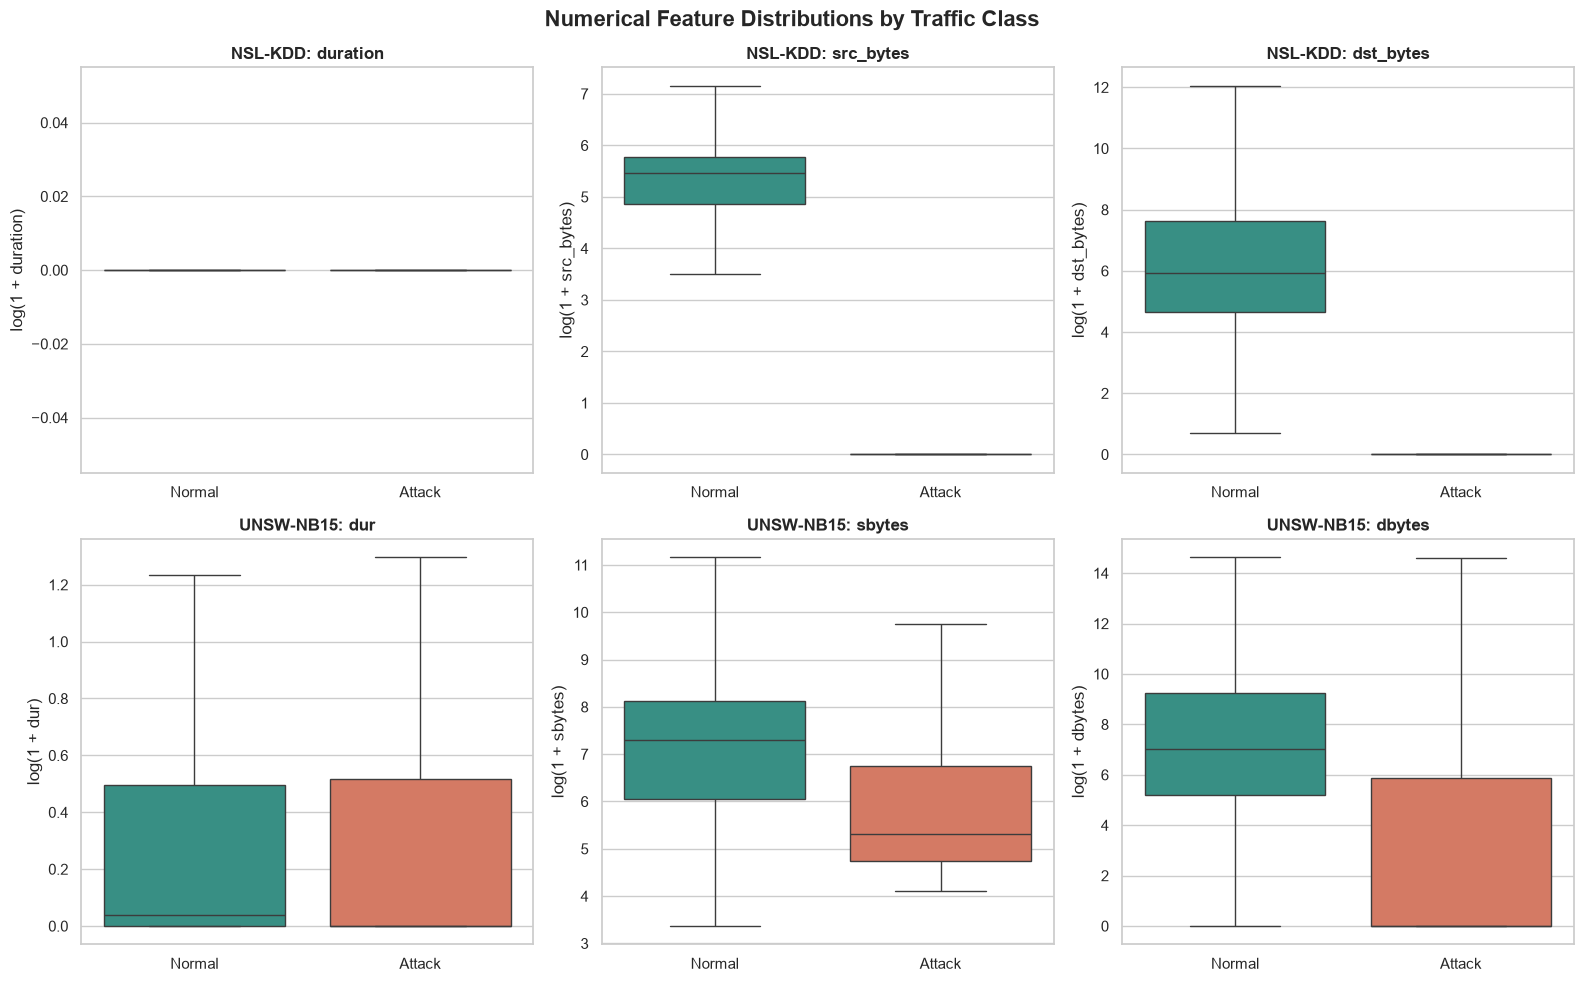

Chart saved: C:\Users\fatim\Documents\network-intrusion-eda\figures\multivariate\numerical_features_by_class.png
File exists: True


In [5]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

plot_configs = [
    (
        "NSL-KDD",
        nsl_analysis,
        ["duration", "src_bytes", "dst_bytes"]
    ),
    (
        "UNSW-NB15",
        unsw_analysis,
        ["dur", "sbytes", "dbytes"]
    )
]

for row_index, (dataset_name, df, features) in enumerate(plot_configs):

    for col_index, feature in enumerate(features):

        ax = axes[row_index, col_index]

        plot_df = pd.DataFrame({
            "Traffic Class": df["traffic_class"],
            "Log Value": np.log1p(df[feature])
        })

        sns.boxplot(
            data=plot_df,
            x="Traffic Class",
            y="Log Value",
            order=["Normal", "Attack"],
            hue="Traffic Class",
            hue_order=["Normal", "Attack"],
            palette={
                "Normal": "#2A9D8F",
                "Attack": "#E76F51"
            },
            showfliers=False,
            legend=False,
            ax=ax
        )

        ax.set_title(
            f"{dataset_name}: {feature}",
            fontweight="bold"
        )

        ax.set_xlabel("")
        ax.set_ylabel(f"log(1 + {feature})")

plt.suptitle(
    "Numerical Feature Distributions by Traffic Class",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

boxplot_path = (
    project_dir
    / "figures"
    / "multivariate"
    / "numerical_features_by_class.png"
)

boxplot_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    boxplot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", boxplot_path)
print("File exists:", boxplot_path.exists())

In [6]:
assert len(class_feature_summary) == 12

assert boxplot_path.exists()

assert nsl_analysis["traffic_class"].notna().all()
assert unsw_analysis["traffic_class"].notna().all()

assert len(nsl_analysis) == 125973
assert len(unsw_analysis) == 175341

print("SUCCESS: M6.1 numerical class comparison validated!")

SUCCESS: M6.1 numerical class comparison validated!


## M6.2 — Categorical Features vs Traffic Class

### Objective

Investigate relationships between categorical network traffic features
and binary traffic labels.

We compare the proportions of Normal and Attack records within each
protocol or connection-state category.

The original dataset records remain unchanged.

In [7]:
categorical_config = {
    "NSL-KDD": {
        "data": nsl_analysis,
        "features": ["protocol_type", "flag"]
    },
    "UNSW-NB15": {
        "data": unsw_analysis,
        "features": ["proto", "state"]
    }
}

attack_rate_tables = {}

for dataset_name, config in categorical_config.items():

    df = config["data"]

    for feature in config["features"]:

        summary = (
            df.groupby(feature)["traffic_class"]
            .agg(
                Total="count",
                Attack=lambda x: (x == "Attack").sum()
            )
            .reset_index()
        )

        summary["Normal"] = (
            summary["Total"] - summary["Attack"]
        )

        summary["Attack Rate (%)"] = (
            summary["Attack"] / summary["Total"] * 100
        ).round(2)

        summary = summary.sort_values(
            "Total",
            ascending=False
        )

        attack_rate_tables[
            (dataset_name, feature)
        ] = summary

        print(f"\n{dataset_name} — {feature}")

        display(summary.head(10))


NSL-KDD — protocol_type


,protocol_type,Total,Attack,Normal,Attack Rate (%)
1,tcp,102689,49089,53600,47.80
2,udp,14993,2559,12434,17.07
0,icmp,8291,6982,1309,84.21



NSL-KDD — flag


,flag,Total,Attack,Normal,Attack Rate (%)
9,SF,74945,11552,63393,15.41
5,S0,34851,34497,354,98.98
1,REJ,11233,8540,2693,76.03
4,RSTR,2421,2275,146,93.97
2,RSTO,1562,1343,219,85.98
6,S1,365,4,361,1.10
10,SH,271,269,2,99.26
7,S2,127,8,119,6.30
3,RSTOS0,103,103,0,100.00
8,S3,49,4,45,8.16



UNSW-NB15 — proto


,proto,Total,Attack,Normal,Attack Rate (%)
113,tcp,79946,40825,39121,51.07
119,udp,63283,49361,13922,78.00
120,unas,12084,12084,0,100.00
6,arp,2859,0,2859,0.00
78,ospf,2595,2531,64,97.53
97,sctp,1150,1150,0,100.00
3,any,300,300,0,100.00
32,gre,225,225,0,100.00
111,swipe,201,201,0,100.00
71,mobile,201,201,0,100.00



UNSW-NB15 — state


,state,Total,Attack,Normal,Attack Rate (%)
3,INT,82275,76560,5715,93.05
2,FIN,77825,40650,37175,52.23
0,CON,13152,1053,12099,8.01
5,REQ,1991,1066,925,53.54
6,RST,83,12,71,14.46
1,ECO,12,0,12,0.00
4,PAR,1,0,1,0.00
7,URN,1,0,1,0.00
8,no,1,0,1,0.00


In [8]:
def plot_category_attack_rates(
    dataset_name,
    feature,
    output_filename,
    top_n=10
):

    summary = attack_rate_tables[
        (dataset_name, feature)
    ].head(top_n).copy()

    plt.figure(figsize=(10, 6))

    ax = sns.barplot(
        data=summary,
        x="Attack Rate (%)",
        y=feature,
        color="#E76F51"
    )

    ax.set_title(
        f"{dataset_name}: Attack Rate by {feature}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Attack Rate (%)")
    ax.set_ylabel(feature)
    ax.set_xlim(0, 105)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            padding=3
        )

    plt.tight_layout()

    output_path = (
        project_dir
        / "figures"
        / "multivariate"
        / output_filename
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path.exists())

    return output_path

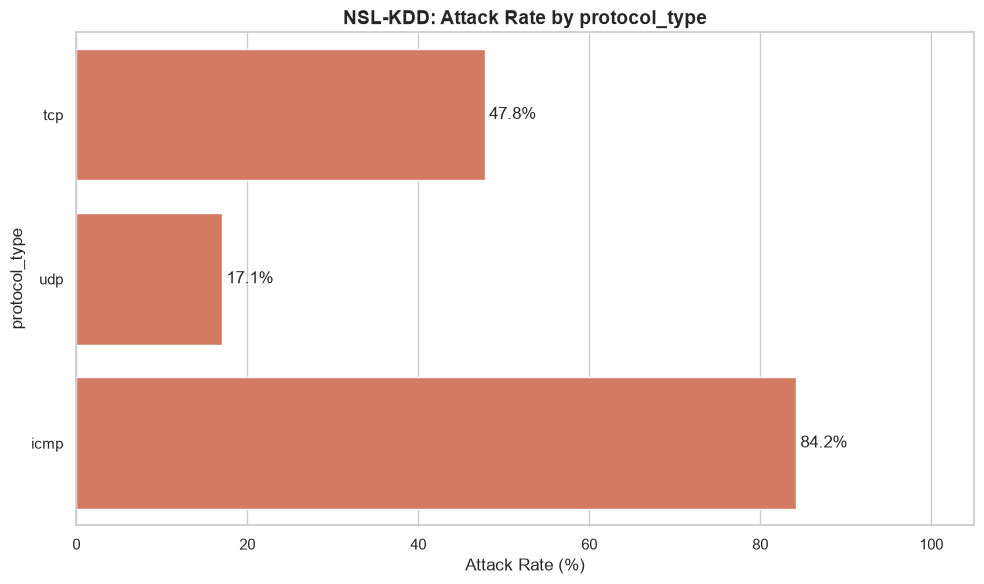

Saved: True


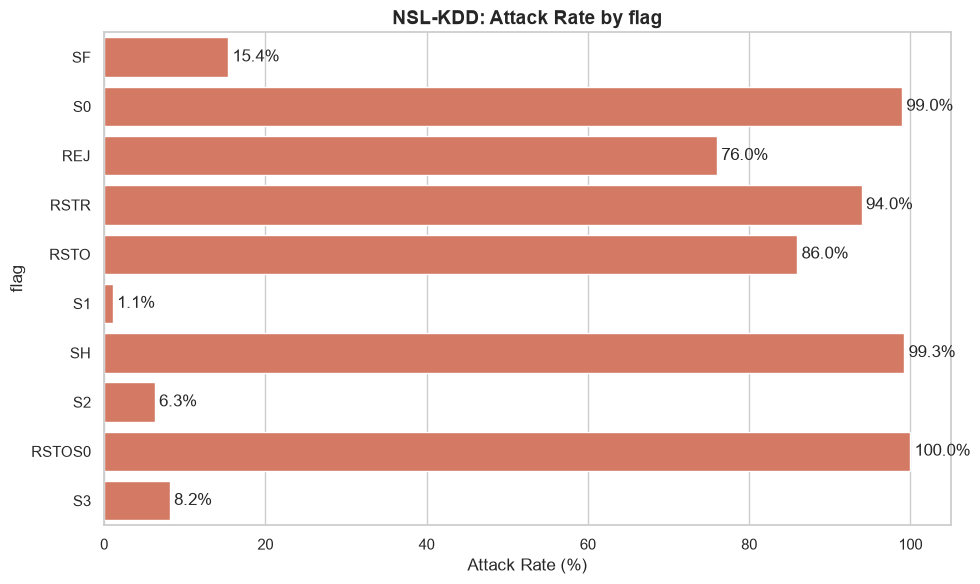

Saved: True


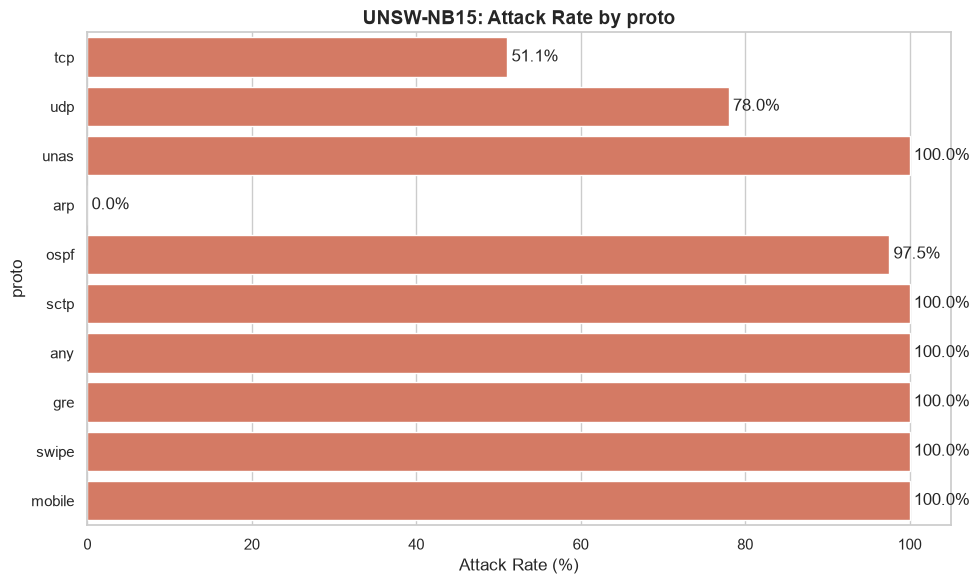

Saved: True


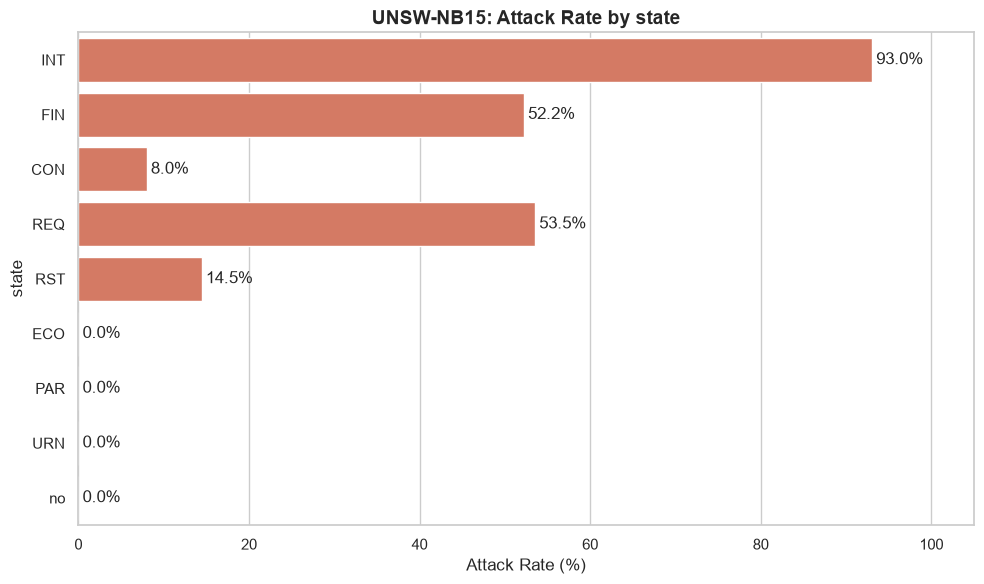

Saved: True


In [9]:
categorical_chart_paths = []

categorical_chart_paths.append(
    plot_category_attack_rates(
        "NSL-KDD",
        "protocol_type",
        "nsl_protocol_attack_rates.png"
    )
)

categorical_chart_paths.append(
    plot_category_attack_rates(
        "NSL-KDD",
        "flag",
        "nsl_flag_attack_rates.png"
    )
)

categorical_chart_paths.append(
    plot_category_attack_rates(
        "UNSW-NB15",
        "proto",
        "unsw_protocol_attack_rates.png"
    )
)

categorical_chart_paths.append(
    plot_category_attack_rates(
        "UNSW-NB15",
        "state",
        "unsw_state_attack_rates.png"
    )
)

In [10]:
for path in categorical_chart_paths:
    assert path.exists(), f"Chart missing: {path}"

for (dataset_name, feature), summary in attack_rate_tables.items():

    assert summary["Total"].sum() == len(
        categorical_config[dataset_name]["data"]
    )

    assert (
        summary["Normal"] + summary["Attack"]
        == summary["Total"]
    ).all()

    assert summary["Attack Rate (%)"].between(
        0, 100
    ).all()

print("SUCCESS: M6.2 categorical analysis validated!")

SUCCESS: M6.2 categorical analysis validated!


In [11]:
print("M6.2 CHART VALIDATION")
print("-" * 40)

for path in categorical_chart_paths:
    print(f"{path.name}: {path.exists()}")

assert len(categorical_chart_paths) == 4
assert all(path.exists() for path in categorical_chart_paths)

for (dataset_name, feature), summary in attack_rate_tables.items():
    df = categorical_config[dataset_name]["data"]

    assert summary["Total"].sum() == len(df)
    assert summary["Attack"].sum() == (df["traffic_class"] == "Attack").sum()
    assert summary["Normal"].sum() == (df["traffic_class"] == "Normal").sum()

print("\nSUCCESS: M6.2 categorical analysis validated!")

M6.2 CHART VALIDATION
----------------------------------------
nsl_protocol_attack_rates.png: True
nsl_flag_attack_rates.png: True
unsw_protocol_attack_rates.png: True
unsw_state_attack_rates.png: True

SUCCESS: M6.2 categorical analysis validated!


## M6.3 — Numerical Feature Correlation Analysis

### Objective

Identify monotonic relationships between selected numerical
network traffic features using Spearman correlation.

Correlation matrices are calculated separately for NSL-KDD
and UNSW-NB15.

Spearman correlation is selected because several numerical
features have highly skewed distributions.

Correlation does not imply causation.

In [12]:
correlation_features = {
    "NSL-KDD": {
        "data": nsl_analysis,
        "features": [
            "duration",
            "src_bytes",
            "dst_bytes",
            "count",
            "srv_count",
            "same_srv_rate",
            "diff_srv_rate",
            "dst_host_count"
        ]
    },

    "UNSW-NB15": {
        "data": unsw_analysis,
        "features": [
            "dur",
            "sbytes",
            "dbytes",
            "spkts",
            "dpkts",
            "rate",
            "sttl",
            "dttl"
        ]
    }
}

for dataset_name, config in correlation_features.items():

    df = config["data"]
    features = config["features"]

    print(f"\n{dataset_name}")

    print("Selected features:", len(features))

    print("Missing values:")
    print(df[features].isna().sum())

    print("Data types:")
    print(df[features].dtypes)


NSL-KDD
Selected features: 8
Missing values:
duration          0
src_bytes         0
dst_bytes         0
count             0
srv_count         0
same_srv_rate     0
diff_srv_rate     0
dst_host_count    0
dtype: int64
Data types:
duration            int64
src_bytes           int64
dst_bytes           int64
count               int64
srv_count           int64
same_srv_rate     float64
diff_srv_rate     float64
dst_host_count      int64
dtype: object

UNSW-NB15
Selected features: 8
Missing values:
dur       0
sbytes    0
dbytes    0
spkts     0
dpkts     0
rate      0
sttl      0
dttl      0
dtype: int64
Data types:
dur       float64
sbytes      int64
dbytes      int64
spkts       int64
dpkts       int64
rate      float64
sttl        int64
dttl        int64
dtype: object


In [13]:
correlation_matrices = {}

for dataset_name, config in correlation_features.items():

    df = config["data"]
    features = config["features"]

    corr_matrix = df[features].corr(
        method="spearman"
    )

    correlation_matrices[dataset_name] = corr_matrix

    print(f"\n{dataset_name} — Spearman Correlation Matrix")

    display(corr_matrix.round(3))


NSL-KDD — Spearman Correlation Matrix


,duration,src_bytes,dst_bytes,count,srv_count,same_srv_rate,diff_srv_rate,dst_host_count
duration,1.000,0.226,0.149,-0.324,-0.319,0.169,-0.140,-0.067
src_bytes,0.226,1.000,0.700,-0.524,-0.053,0.753,-0.705,-0.405
dst_bytes,0.149,0.700,1.000,-0.440,-0.017,0.630,-0.608,-0.342
count,-0.324,-0.524,-0.440,1.000,0.519,-0.720,0.617,0.620
srv_count,-0.319,-0.053,-0.017,0.519,1.000,0.032,-0.039,0.218
same_srv_rate,0.169,0.753,0.630,-0.720,0.032,1.000,-0.920,-0.541
diff_srv_rate,-0.140,-0.705,-0.608,0.617,-0.039,-0.920,1.000,0.526
dst_host_count,-0.067,-0.405,-0.342,0.620,0.218,-0.541,0.526,1.000



UNSW-NB15 — Spearman Correlation Matrix


,dur,sbytes,dbytes,spkts,dpkts,rate,sttl,dttl
dur,1.000,0.752,0.757,0.821,0.769,-0.879,-0.308,0.818
sbytes,0.752,1.000,0.792,0.901,0.812,-0.581,-0.395,0.678
dbytes,0.757,0.792,1.000,0.888,0.990,-0.635,-0.662,0.823
spkts,0.821,0.901,0.888,1.000,0.910,-0.634,-0.437,0.748
dpkts,0.769,0.812,0.990,0.910,1.000,-0.639,-0.630,0.832
rate,-0.879,-0.581,-0.635,-0.634,-0.639,1.000,0.362,-0.775
sttl,-0.308,-0.395,-0.662,-0.437,-0.630,0.362,1.000,-0.333
dttl,0.818,0.678,0.823,0.748,0.832,-0.775,-0.333,1.000


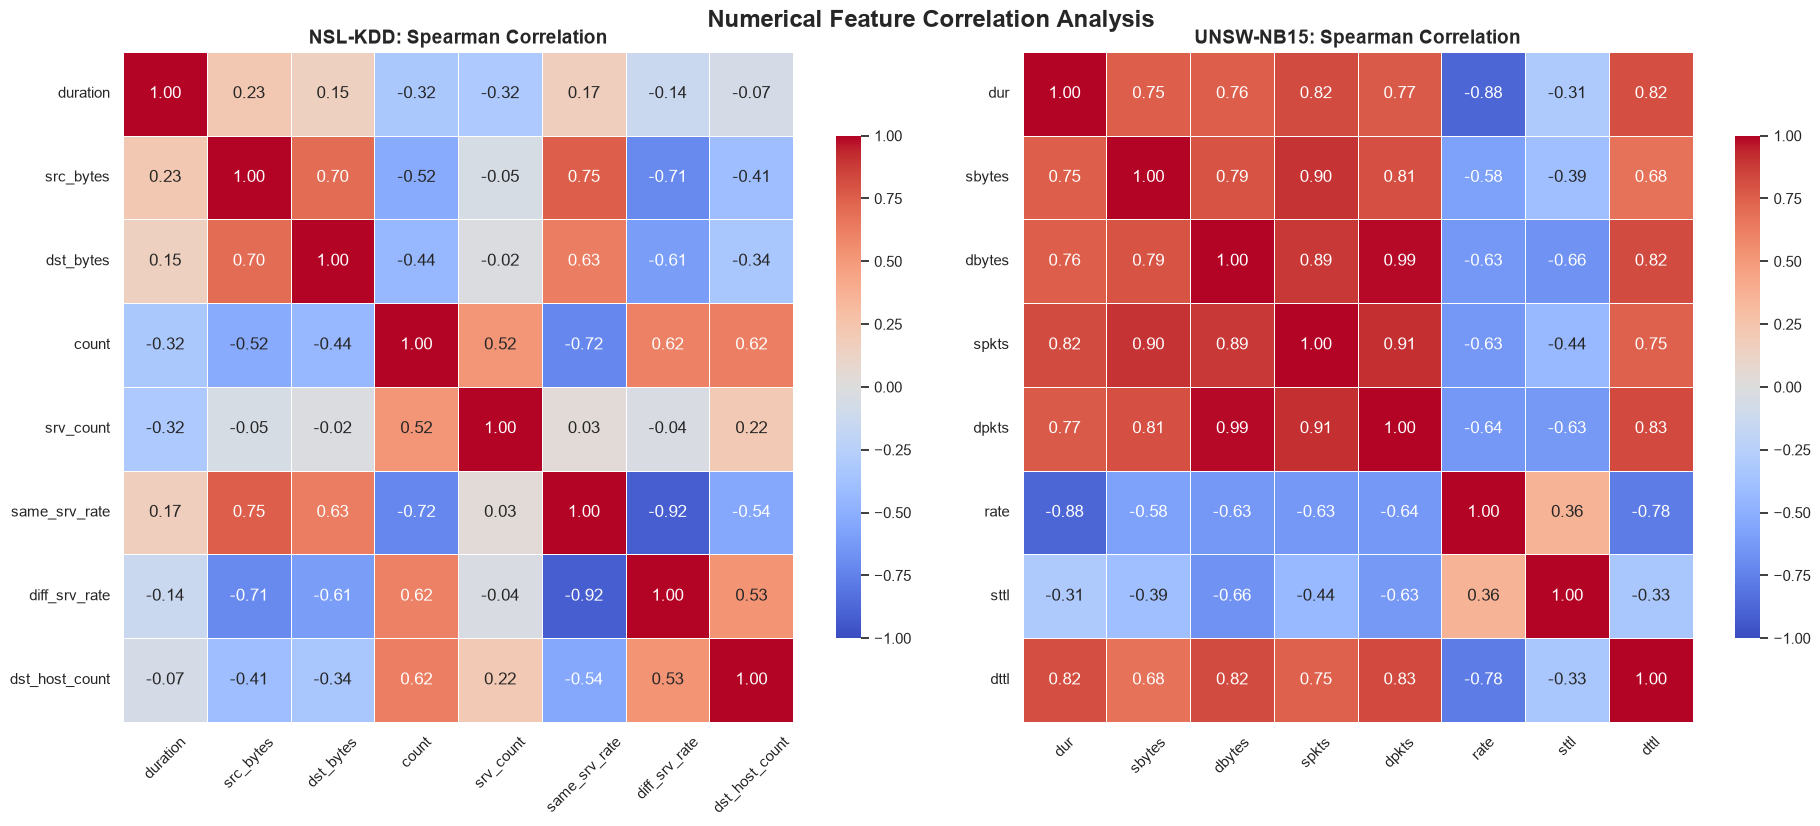

Chart saved: C:\Users\fatim\Documents\network-intrusion-eda\figures\multivariate\spearman_correlation_heatmaps.png
File exists: True


In [14]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 8)
)

for ax, (dataset_name, corr_matrix) in zip(
    axes,
    correlation_matrices.items()
):

    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        ax=ax,
        cbar_kws={"shrink": 0.75}
    )

    ax.set_title(
        f"{dataset_name}: Spearman Correlation",
        fontsize=14,
        fontweight="bold"
    )

    ax.tick_params(
        axis="x",
        rotation=45
    )

    ax.tick_params(
        axis="y",
        rotation=0
    )

plt.suptitle(
    "Numerical Feature Correlation Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

correlation_chart_path = (
    project_dir
    / "figures"
    / "multivariate"
    / "spearman_correlation_heatmaps.png"
)

correlation_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    correlation_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", correlation_chart_path)
print("File exists:", correlation_chart_path.exists())

In [15]:
strong_correlation_results = []

for dataset_name, corr_matrix in correlation_matrices.items():

    features = corr_matrix.columns.tolist()

    for i in range(len(features)):

        for j in range(i + 1, len(features)):

            feature_1 = features[i]
            feature_2 = features[j]

            correlation = corr_matrix.loc[
                feature_1,
                feature_2
            ]

            if pd.notna(correlation):

                strong_correlation_results.append({
                    "Dataset": dataset_name,
                    "Feature 1": feature_1,
                    "Feature 2": feature_2,
                    "Spearman Correlation": correlation,
                    "Absolute Correlation": abs(correlation)
                })

strong_corr_df = pd.DataFrame(
    strong_correlation_results
)

strong_corr_df = strong_corr_df.sort_values(
    ["Dataset", "Absolute Correlation"],
    ascending=[True, False]
)

for dataset_name in correlation_matrices:

    print(f"\n{dataset_name} — Top 5 Strongest Relationships")

    display(
        strong_corr_df[
            strong_corr_df["Dataset"] == dataset_name
        ].head(5).round(3)
    )


NSL-KDD — Top 5 Strongest Relationships


,Dataset,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
25,NSL-KDD,same_srv_rate,diff_srv_rate,-0.920,0.920
10,NSL-KDD,src_bytes,same_srv_rate,0.753,0.753
19,NSL-KDD,count,same_srv_rate,-0.720,0.720
11,NSL-KDD,src_bytes,diff_srv_rate,-0.705,0.705
7,NSL-KDD,src_bytes,dst_bytes,0.700,0.700



UNSW-NB15 — Top 5 Strongest Relationships


,Dataset,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
42,UNSW-NB15,dbytes,dpkts,0.990,0.990
46,UNSW-NB15,spkts,dpkts,0.910,0.910
36,UNSW-NB15,sbytes,spkts,0.901,0.901
41,UNSW-NB15,dbytes,spkts,0.888,0.888
32,UNSW-NB15,dur,rate,-0.879,0.879


In [16]:
assert correlation_chart_path.exists()

assert len(correlation_matrices) == 2

for dataset_name, corr_matrix in correlation_matrices.items():

    assert corr_matrix.shape == (8, 8), (
        f"Unexpected matrix shape: {dataset_name}"
    )

    assert np.allclose(
        corr_matrix.values,
        corr_matrix.values.T,
        equal_nan=True
    ), f"Matrix is not symmetric: {dataset_name}"

    assert (
        (corr_matrix.stack() >= -1).all()
        and
        (corr_matrix.stack() <= 1).all()
    ), f"Invalid correlation values: {dataset_name}"

print("SUCCESS: M6.3 correlation analysis validated!")

SUCCESS: M6.3 correlation analysis validated!


## M6.4 — Feature Relationships by Traffic Class

### Objective

Investigate whether selected numerical feature relationships
differ between Normal and Attack records.

The analysis uses:
- Class-specific Spearman correlations
- Log-transformed scatterplots
- Separate analysis for NSL-KDD and UNSW-NB15

Scatterplot sampling is used only for visualization.
Correlation calculations use all available training records.

In [17]:
relationship_config = {
    "NSL-KDD": {
        "data": nsl_analysis,
        "x": "src_bytes",
        "y": "dst_bytes"
    },
    "UNSW-NB15": {
        "data": unsw_analysis,
        "x": "sbytes",
        "y": "spkts"
    }
}

relationship_results = []

for dataset_name, config in relationship_config.items():

    df = config["data"]
    x_feature = config["x"]
    y_feature = config["y"]

    for traffic_class in ["Normal", "Attack"]:

        subset = df[
            df["traffic_class"] == traffic_class
        ]

        correlation = subset[
            [x_feature, y_feature]
        ].corr(method="spearman").iloc[0, 1]

        relationship_results.append({
            "Dataset": dataset_name,
            "Feature 1": x_feature,
            "Feature 2": y_feature,
            "Traffic Class": traffic_class,
            "Records": len(subset),
            "Spearman Correlation": correlation
        })

relationship_df = pd.DataFrame(relationship_results)

display(relationship_df.round(3))

,Dataset,Feature 1,Feature 2,Traffic Class,Records,Spearman Correlation
0,NSL-KDD,src_bytes,dst_bytes,Normal,67343,0.312
1,NSL-KDD,src_bytes,dst_bytes,Attack,58630,0.353
2,UNSW-NB15,sbytes,spkts,Normal,56000,0.919
3,UNSW-NB15,sbytes,spkts,Attack,119341,0.849


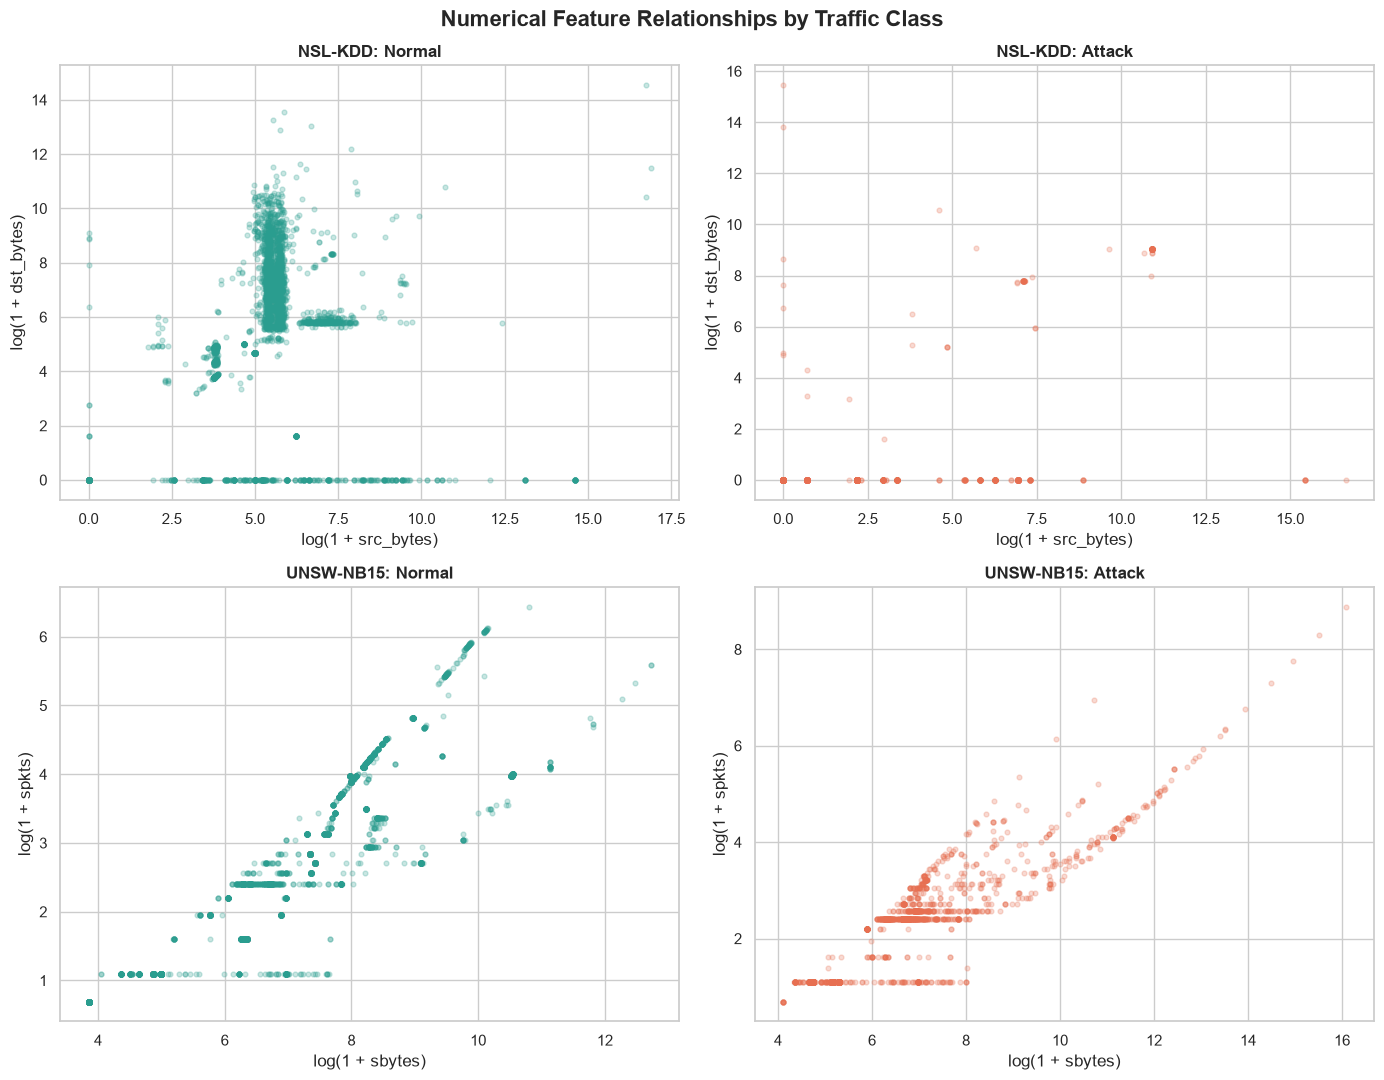

Chart saved: C:\Users\fatim\Documents\network-intrusion-eda\figures\multivariate\feature_relationships_by_class.png
File exists: True


In [18]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11)
)

colors = {
    "Normal": "#2A9D8F",
    "Attack": "#E76F51"
}

for row_index, (dataset_name, config) in enumerate(
    relationship_config.items()
):

    df = config["data"]
    x_feature = config["x"]
    y_feature = config["y"]

    for col_index, traffic_class in enumerate(
        ["Normal", "Attack"]
    ):

        ax = axes[row_index, col_index]

        subset = df[
            df["traffic_class"] == traffic_class
        ]

        sample_df = subset.sample(
            n=min(3000, len(subset)),
            random_state=42
        )

        ax.scatter(
            np.log1p(sample_df[x_feature]),
            np.log1p(sample_df[y_feature]),
            alpha=0.25,
            s=12,
            color=colors[traffic_class]
        )

        ax.set_title(
            f"{dataset_name}: {traffic_class}",
            fontweight="bold"
        )

        ax.set_xlabel(f"log(1 + {x_feature})")
        ax.set_ylabel(f"log(1 + {y_feature})")

plt.suptitle(
    "Numerical Feature Relationships by Traffic Class",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

relationship_chart_path = (
    project_dir
    / "figures"
    / "multivariate"
    / "feature_relationships_by_class.png"
)

relationship_chart_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    relationship_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved:", relationship_chart_path)
print("File exists:", relationship_chart_path.exists())

In [19]:
assert len(relationship_df) == 4

assert relationship_chart_path.exists()

assert relationship_df[
    "Spearman Correlation"
].notna().all()

assert relationship_df[
    "Spearman Correlation"
].between(-1, 1).all()

for dataset_name, config in relationship_config.items():

    expected_count = len(config["data"])

    actual_count = relationship_df.loc[
        relationship_df["Dataset"] == dataset_name,
        "Records"
    ].sum()

    assert actual_count == expected_count

print("SUCCESS: M6.4 feature relationship analysis validated!")

SUCCESS: M6.4 feature relationship analysis validated!


In [20]:
from pathlib import Path

expected_files = [
    "numerical_features_by_class.png",
    "nsl_protocol_attack_rates.png",
    "nsl_flag_attack_rates.png",
    "unsw_protocol_attack_rates.png",
    "unsw_state_attack_rates.png",
    "spearman_correlation_heatmaps.png",
    "feature_relationships_by_class.png"
]

figures_dir = project_dir / "figures" / "multivariate"

for filename in expected_files:
    path = figures_dir / filename
    print(f"{filename}: {path.exists()}")
    assert path.exists(), f"Missing: {filename}"

print("\nSUCCESS: All M6 visualization files verified!")

numerical_features_by_class.png: True
nsl_protocol_attack_rates.png: True
nsl_flag_attack_rates.png: True
unsw_protocol_attack_rates.png: True
unsw_state_attack_rates.png: True
spearman_correlation_heatmaps.png: True
feature_relationships_by_class.png: True

SUCCESS: All M6 visualization files verified!
